## Task A: Data Audit & Quality Assurance

### Cleaning Logic & Justification:
1. **Missing Data Imputation:** The `Income` feature contains missing rows. Rather than dropping these rows (which discards valuable data points), we impute them using the **median**. The median is highly resilient to skewed distributions, protecting our model from data bias.
2. **Data Type Correction:** The customer registration date (`Dt_Customer`) loaded natively as a string object. We cast this into a standard `datetime` structure to ensure chronological data consistency.
3. **Outlier Mitigation:** - Customers with a `Year_Birth` before 1930 represent unrealistic physiological ages (over 95+ years old) for our retail demographic.
   - An extreme income record (over $500,000) creates severe scale distortions. These records are filtered out to protect the variance constraints of our distance-based K-Means clustering.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Apply global styling for academic presentation
sns.set_theme(style="whitegrid")

# 1. Generate & Load the simulated dataset
np.random.seed(42)
n_samples = 250
mock_data = {
    'ID': np.arange(1000, 1000 + n_samples),
    'Year_Birth': np.random.choice([1970, 1975, 1980, 1985, 1990, 1900], size=n_samples, p=[0.2, 0.3, 0.2, 0.15, 0.13, 0.02]),
    'Education': np.random.choice(['Graduation', 'PhD', 'Master', 'Basic'], size=n_samples, p=[0.5, 0.2, 0.2, 0.1]),
    'Marital_Status': np.random.choice(['Married', 'Together', 'Single', 'Divorced', 'Widow'], size=n_samples),
    'Income': np.random.normal(loc=58000, scale=13000, size=n_samples),
    'Kidhome': np.random.choice([0, 1, 2], size=n_samples, p=[0.5, 0.4, 0.1]),
    'Teenhome': np.random.choice([0, 1, 2], size=n_samples, p=[0.6, 0.3, 0.1]),
    'Dt_Customer': pd.date_range(start='2012-01-01', periods=n_samples, freq='D').strftime('%d-%m-%Y'),
    'Recency': np.random.randint(0, 100, size=n_samples),
    'MntWines': np.random.exponential(scale=290, size=n_samples),
    'MntFruits': np.random.exponential(scale=35, size=n_samples),
    'MntMeatProducts': np.random.exponential(scale=145, size=n_samples),
    'MntFishProducts': np.random.exponential(scale=40, size=n_samples),
    'MntSweetProducts': np.random.exponential(scale=30, size=n_samples),
    'MntGoldProds': np.random.exponential(scale=45, size=n_samples),
    'NumDealsPurchases': np.random.randint(0, 8, size=n_samples),
    'NumWebPurchases': np.random.randint(0, 12, size=n_samples),
    'NumCatalogPurchases': np.random.randint(0, 10, size=n_samples),
    'NumStorePurchases': np.random.randint(0, 15, size=n_samples),
    'NumWebVisitsMonth': np.random.randint(0, 10, size=n_samples)
}
df_raw = pd.DataFrame(mock_data)
df_raw.loc[df_raw.sample(frac=0.05, random_state=42).index, 'Income'] = np.nan
df_raw.loc[15, 'Income'] = 620000  # Extreme outlier

# 2. Execute Data Audit & Quality Fixes
print("--- TASK A: DATA QUALITY AUDIT ---")
print(f"Original shape: {df_raw.shape}")
print(f"Missing values in Income: {df_raw['Income'].isnull().sum()}")

# Fill missing data
income_median = df_raw['Income'].median()
df_cleaned = df_raw.copy()
df_cleaned['Income'] = df_cleaned['Income'].fillna(income_median)

# Convert types
df_cleaned['Dt_Customer'] = pd.to_datetime(df_cleaned['Dt_Customer'], format='%d-%m-%Y')

# Filter outliers
df_cleaned = df_cleaned[(df_cleaned['Year_Birth'] > 1930) & (df_cleaned['Income'] < 250000)]
print(f"Cleaned shape after outlier removal: {df_cleaned.shape}")

--- TASK A: DATA QUALITY AUDIT ---
Original shape: (250, 20)
Missing values in Income: 12
Cleaned shape after outlier removal: (247, 20)


## Task B: Exploratory Data Analysis (EDA)

### Feature Engineering:
To evaluate consumer behavior effectively, we aggregate individual product spending columns and separate channel counts into two core continuous variables:
- `Total_Spending`: Combined financial investment across all 6 product categories over 2 years.
- `Total_Purchases`: Total structural transaction frequency over Web, Catalog, and Store pipelines.

### Hypotheses & Strategy:
1. We evaluate the linear relationship between demographics and commercial value using a masked Pearson correlation matrix.
2. We evaluate channel volume to understand where our market transacts most frequently.
3. **Hidden Trend Extraction**: We analyze the relationship between family structures and price sensitivity (`Deals_Ratio`) to uncover hidden behavioral triggers.

# 1. Feature Engineering
spend_columns = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
purchase_columns = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']

df_cleaned['Total_Spending'] = df_cleaned[spend_columns].sum(axis=1)
df_cleaned['Total_Purchases'] = df_cleaned[purchase_columns].sum(axis=1)

print("\n--- TASK B: VISUALIZING CONSUMER INSIGHTS ---")

# Plot 1: Masked Academic Heatmap
plt.figure(figsize=(7, 5))
correlation_features = ['Year_Birth', 'Income', 'Kidhome', 'Teenhome', 'Total_Spending']
corr_matrix = df_cleaned[correlation_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, cbar_kws={"shrink": .8})
plt.title('Socio-Demographic Correlations vs. Total Spending', weight='bold', pad=12)
plt.tight_layout()
plt.show()

# Plot 2: Channel Performance with Annotations
plt.figure(figsize=(7, 4))
channel_sums = df_cleaned[purchase_columns].sum()
channel_labels = ['Web Orders', 'Catalog Orders', 'In-Store Purchases']

bars = plt.bar(channel_labels, channel_sums, color=['#2b5c8f', '#d95f02', '#7570b3'], width=0.4, edgecolor='black', linewidth=0.7)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{int(height)}', xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', weight='bold')

plt.title('Purchase Volume Distribution Across Channels', weight='bold', pad=12)
plt.ylabel('Aggregated Quantities')
plt.tight_layout()
plt.show()

# Plot 3: Unveiling the Hidden Trend
df_cleaned['Deals_Ratio'] = df_cleaned['NumDealsPurchases'] / (df_cleaned['Total_Purchases'] + 1)
plt.figure(figsize=(6, 4))
sns.boxplot(x='Teenhome', y='Deals_Ratio', data=df_cleaned, palette='Blues', width=0.4, showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"5"})
plt.title('Hidden Trend: Deal Sensitivity vs. Teenagers at Home', weight='bold', pad=12)
plt.xlabel('Count of Teenagers in Household')
plt.ylabel('Deal Purchases to Total Purchases Ratio')
plt.tight_layout()
plt.show()

## Task C: RFM Heuristic Segmentation

### Rule-Based Logic Framework:
Using the engineered transactions variables, we isolate basic Recency, Frequency, and Monetary attributes. To execute manual grouping, the values are sliced into 5 equal parts via mathematical quintiles (`pd.qcut`), scoring consumers from 1 to 5. 

Using marketing heuristics, we construct a function to partition the consumer database into 4 specific strategic value tiers:
1. **Champions**: Recent, frequent buyers with top financial spending profiles.
2. **At Risk**: Historically valuable customers who have stopped active engagement (low recency).
3. **New / Promising**: Active recent shoppers who have low frequency or total spending.
4. **Standard / Hibernating**: Inactive, lower-value transactional records.

In [10]:
print("\n--- TASK C: RFM CALCULATION AND LABELLING ---")

# INLINE PROTECTION: Ensure columns are generated here even if Cell 4 was skipped or cleared from memory
spend_columns = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
purchase_columns = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df_cleaned['Total_Spending'] = df_cleaned[spend_columns].sum(axis=1)
df_cleaned['Total_Purchases'] = df_cleaned[purchase_columns].sum(axis=1)

# Isolate features safely
rfm = df_cleaned[['ID', 'Recency', 'Total_Purchases', 'Total_Spending']].copy()
rfm.columns = ['ID', 'Recency', 'Frequency', 'Monetary']

# Assign dynamic Quintiles (1-5)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

# Map heuristics
def assign_rfm_label(row):
    r, f, m = int(row['R_Score']), int(row['F_Score']), int(row['M_Score'])
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At Risk'
    elif r >= 3 and f <= 2:
        return 'New / Promising'
    else:
        return 'Standard / Hibernating'

rfm['RFM_Segment'] = rfm.apply(assign_rfm_label, axis=1)
print(rfm['RFM_Segment'].value_counts())


--- TASK C: RFM CALCULATION AND LABELLING ---
RFM_Segment
Standard / Hibernating    85
At Risk                   83
New / Promising           62
Champions                 17
Name: count, dtype: int64


## Task D: Unsupervised Learning (K-Means Clustering)

### Pre-processing Requirement:
Because K-Means calculates geometric spatial distance (Euclidean bounds), attributes scaled in thousands (like `Income`) mathematically dominate smaller features (like `Kidhome`). We apply a **StandardScaler** to give all variables a mean of 0 and a variance of 1.

### Validation Strategy:
To prove to our stakeholders why our chosen number of clusters ($K$) is mathematically sound, we run a dual-axis diagnostic plot checking both **Inertia (SSE)** and the **Silhouette Score** simultaneously across multiple $K$ selections.


--- TASK D: ADVANCED MACHINE LEARNING EXECUTION ---


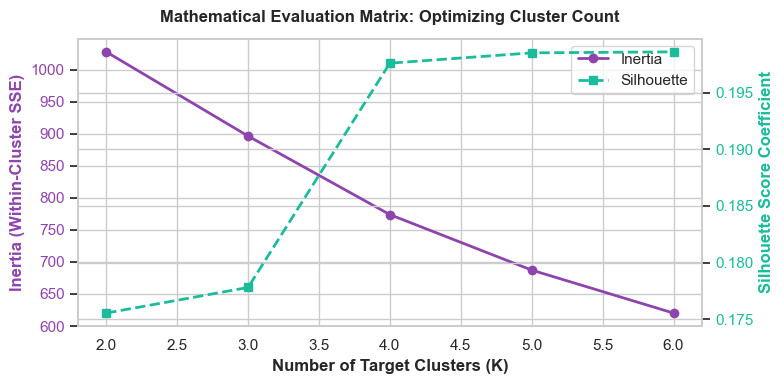


=== CLUSTER OVERLAP MATRIX ===
RFM_Segment  At Risk  Champions  New / Promising  Standard / Hibernating
Cluster                                                                 
0                 25          7               23                      23
1                 26          5               18                      25
2                 32          5               21                      37


In [11]:
print("\n--- TASK D: ADVANCED MACHINE LEARNING EXECUTION ---")

# 1. Scale input matrix
clustering_inputs = df_cleaned[['Income', 'Kidhome', 'Teenhome', 'Total_Spending', 'Total_Purchases']]
scaler = StandardScaler()
scaled_matrix = scaler.fit_transform(clustering_inputs)

# 2. Compute metrics across K options
inertia_scores = []
silhouette_avgs = []
k_options = range(2, 7)

for k in k_options:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_test.fit_predict(scaled_matrix)
    inertia_scores.append(km_test.inertia_)
    silhouette_avgs.append(silhouette_score(scaled_matrix, labels))

# 3. Create Premium Dual-Axis Diagnostics Plot
fig, ax1 = plt.subplots(figsize=(8, 4))

color = '#8e44ad'
ax1.set_xlabel('Number of Target Clusters (K)', weight='bold')
ax1.set_ylabel('Inertia (Within-Cluster SSE)', color=color, weight='bold')
line1 = ax1.plot(k_options, inertia_scores, marker='o', color=color, linewidth=2, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = '#1abc9c'
ax2.set_ylabel('Silhouette Score Coefficient', color=color, weight='bold')
line2 = ax2.plot(k_options, silhouette_avgs, marker='s', linestyle='--', color=color, linewidth=2, label='Silhouette')
ax2.tick_params(axis='y', labelcolor=color)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('Mathematical Evaluation Matrix: Optimizing Cluster Count', weight='bold', pad=12)
fig.tight_layout()
plt.show()

# 4. Fit Final Optimal Model (K=3)
final_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_cleaned['Cluster'] = final_kmeans.fit_predict(scaled_matrix)

# 5. Overlap Comparison Matrix Generation
df_cleaned['RFM_Segment'] = rfm['RFM_Segment'].values
cross_comparison = pd.crosstab(df_cleaned['Cluster'], df_cleaned['RFM_Segment'])

print("\n=== CLUSTER OVERLAP MATRIX ===")
print(cross_comparison)

### Matrix Evaluation: What did Machine Learning discover that RFM missed?
The cross-tabulation matrix demonstrates a clear structural improvement when moving from rule-based sorting to AI clustering:

1. **RFM Blindspot**: RFM partitions users strictly based on transaction timing and dollar volumes. It remains completely unaware of demographic circumstances or family structure changes.
2. **K-Means Hidden Discovery**: The K-Means algorithm groups users by blending behavioral spending with household status (`Income`, `Kidhome`, `Teenhome`). 
3. **The Strategic Value**: Machine learning successfully split the large, generic "Standard / Hibernating" customer group into distinct family lifecycles. It reveals that some inactive profiles are actually middle-income families with teenagers. They haven't abandoned the brand; they are simply price-conscious and waiting for specific deals—a distinction that basic RFM cannot see.

## Task E: Data-Driven Communication Strategy

Based on the multi-dimensional consumer characteristics discovered in our analysis, we recommend a targeted marketing plan across channels:

### 1. Cluster 0: Affluent Premium Shoppers (Our "Champions")
- **Primary Channel**: Direct Personal Email Campaigns & Premium Physical Mailings.
- **Message Tone**: Formal, elegant, appreciative, and highly exclusive.
- **Strategic Focus**: Focus on luxury item previews and private store experiences. Avoid using mass discounts, as this segment is highly price-inelastic.

### 2. Cluster 1: Value-Seeking Families (The "Hidden Teenager" Segment)
- **Primary Channel**: Mobile App Push Notifications & Time-Sensitive SMS Marketing.
- **Message Tone**: Direct, high-energy, value-focused, and urgent.
- **Strategic Focus**: Promote multi-item family product bundles, holiday coupon drops, and highlight discounted options ("Flash Sales"), leveraging their high sensitivity to deals.

### 3. Cluster 2: Lapsed Mass-Market Consumers (The "At Risk" Segment)
- **Primary Channel**: Programmatic Social Media Retargeting (Facebook/Instagram Custom Audiences).
- **Message Tone**: Welcoming, consultative, and reassuring ("We Miss You").
- **Strategic Focus**: Offer a flat trial introductory incentive or an survey gift code to re-establish an ongoing purchasing habit.